In [ ]:
!pip install datasets
import re
import nltk
import numpy as np
import torch
import random

from nltk.corpus import reuters
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import random
import pandas as pd

from datasets import Dataset








import matplotlib.pyplot as plt
import seaborn as sns


import logging
from sentence_transformers.evaluation import EmbeddingSimilarityEvaluator
from sentence_transformers.trainer import SentenceTransformerTrainer
from sentence_transformers import SentenceTransformer, InputExample, losses, evaluation, util
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
 #Download NLTK data files (run once)
nltk.download('reuters')
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('omw-1.4')
nltk.download('wordnet')
nltk.download('punkt_tab')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 487.4/487.4 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 kB 12.4 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.0
    Uninstalling fsspec-2025.3.0:
      Successfully uninstalled fsspec-2025.3.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.12.0 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cublas-cu12==12.4.5.8; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cublas-cu12 12.5.3.2 which is

[nltk_data] Downloading package reuters to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
# Get file IDs and categories
file_ids = reuters.fileids()
categories = reuters.categories()

# Load articles and their labels
articles = [reuters.raw(file_id) for file_id in file_ids]
labels = [reuters.categories(file_id)[0] for file_id in file_ids]  # Use the first category as the label

# Create a DataFrame for easier analysis
df = pd.DataFrame({'text': articles, 'label': labels})

### 1.2. Basic Statistics

In [ ]:
df.head(10)

,text,label
0,ASIAN EXPORTERS FEAR DAMAGE FROM U.S.-JAPAN RI...,trade
1,CHINA DAILY SAYS VERMIN EAT 7-12 PCT GRAIN STO...,grain
2,JAPAN TO REVISE LONG-TERM ENERGY DEMAND DOWNWA...,crude
3,THAI TRADE DEFICIT WIDENS IN FIRST QUARTER\n ...,corn
4,INDONESIA SEES CPO PRICE RISING SHARPLY\n Ind...,palm-oil
5,AUSTRALIAN FOREIGN SHIP BAN ENDS BUT NSW PORTS...,ship
6,INDONESIAN COMMODITY EXCHANGE MAY EXPAND\n Th...,coffee
7,SRI LANKA GETS USDA APPROVAL FOR WHEAT PRICE\n...,grain
8,WESTERN MINING TO OPEN NEW GOLD MINE IN AUSTRA...,gold
9,SUMITOMO BANK AIMS AT QUICK RECOVERY FROM MERG...,acq


In [ ]:
df.describe()

,text,label
count,10788,10788
unique,10657,79
top,26-FEB-1987\n 26-FEB-1987\n\n,earn
freq,7,3926


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10788 entries, 0 to 10787
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    10788 non-null  object
 1   label   10788 non-null  object
dtypes: object(2)
memory usage: 168.7+ KB


In [ ]:
df.isnull().sum()

,0
text,0
label,0


Total articles: 10788
Unique categories: 79
label
earn             3926
acq              2369
crude             552
interest          453
money-fx          362
                 ... 
copra-cake          1
groundnut-oil       1
cotton-oil          1
sun-oil             1
rand                1
Name: count, Length: 79, dtype: int64


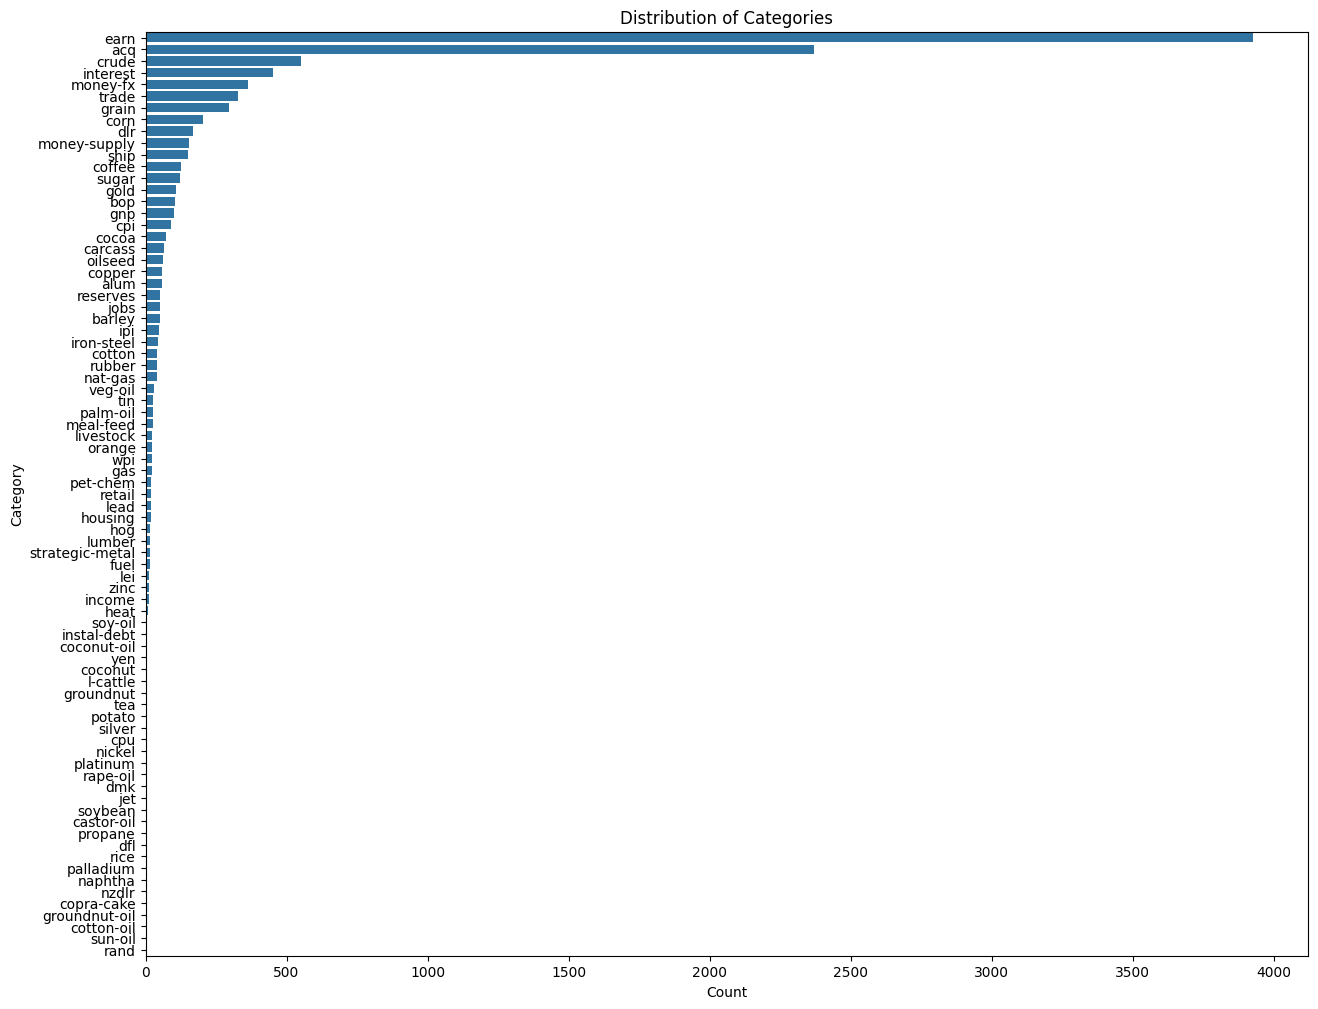

In [ ]:
# Number of articles
print(f"Total articles: {len(df)}")

# Number of unique categories
print(f"Unique categories: {df['label'].nunique()}")

# Distribution of categories
print(df['label'].value_counts())

# Plot the distribution of categories
plt.figure(figsize=(15, 12))
sns.countplot(y=df['label'], order=df['label'].value_counts().index)
plt.title("Distribution of Categories")
plt.xlabel("Count")
plt.ylabel("Category")
plt.show()

label
earn             3926
acq              2369
crude             552
interest          453
money-fx          362
                 ... 
copra-cake          1
groundnut-oil       1
cotton-oil          1
sun-oil             1
rand                1
Name: count, Length: 79, dtype: int64


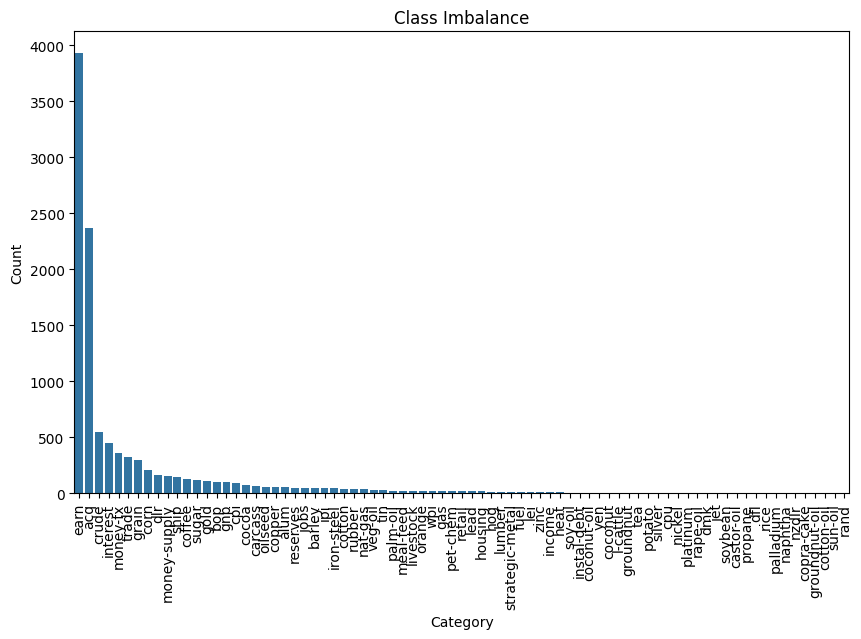

In [ ]:
# Check class imbalance
category_counts = df['label'].value_counts()
print(category_counts)

# Plot class imbalance
plt.figure(figsize=(10, 6))
sns.barplot(x=category_counts.index, y=category_counts.values)
plt.title("Class Imbalance")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()

In [ ]:
lemmatizer = WordNetLemmatizer()
def preprocess(text):
    stop_words = set(stopwords.words('english'))
    """
    Preprocesses the input text by:
    1. Converting to lowercase.
    2. Removing special characters and numbers.
    3. Tokenizing into words.
    4. Lemmatizing words.
    """
    # Lowercase the text
    text = text.lower()
    # Remove special characters and numbers
    text = re.sub(r"[^a-zA-Z0-9']", " ", text)
    # Tokenize into words
    words = word_tokenize(text)
    # Remove single-character words
    words = [word for word in words if len(word) > 1]
    # Remove stopwords
    words = [word for word in words if word not in stop_words]
    # Lemmatize words
    words = [lemmatizer.lemmatize(word) for word in words]
    return ' '.join(words)

# Apply preprocessing to the dataset
df['cleaned_text'] = df['text'].apply(preprocess)

In [ ]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

In [ ]:
# Use the first sentence as the query
train_df['query'] = train_df['cleaned_text'].apply(lambda x: x.split('.')[0])

# Create synthetic pairs with harder negatives
query_article_pairs = []
for i, row in train_df.iterrows():
    query = row['query']
    article = row['cleaned_text']

    # Positive Pair (same article)
    relevant_pair = (query, article, 1.0)
    query_article_pairs.append(relevant_pair)

    # Negative Pair (completely different category)
    random_row = train_df[train_df['label'] != row['label']].sample(1).iloc[0]
    irrelevant_pair = (query, random_row['cleaned_text'], 0.0)
    query_article_pairs.append(irrelevant_pair)

    # Harder Negative Pair (same category but different meaning)
    similar_rows = train_df[(train_df['label'] == row['label']) & (train_df.index != i)]
    if not similar_rows.empty:
        hard_negative_row = similar_rows.sample(1).iloc[0]  # Pick a similar but different article
        hard_negative_pair = (query, hard_negative_row['cleaned_text'], 0.5)  # Label as semi-relevant
        query_article_pairs.append(hard_negative_pair)

# Split into train and validation pairs
train_pairs, val_pairs = train_test_split(query_article_pairs, test_size=0.2, random_state=42)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Load a pre-trained SBERT model
model = SentenceTransformer('all-MiniLM-L6-v2')

# Convert training pairs to InputExample format
train_examples = [InputExample(texts=[query, article], label=float(similarity)) for query, article, similarity in train_pairs]


# Convert validation pairs to InputExample format
val_examples = [InputExample(texts=[query, article], label=float(similarity)) for query, article, similarity in val_pairs]

train_dataloader = DataLoader(train_examples, shuffle=True, batch_size=128)

# Use MultipleNegativesRankingLoss instead of CosineSimilarityLoss
train_loss = losses.CosineSimilarityLoss(model=model)

# Fine-tune the model with validation
model.fit(
    train_objectives=[(train_dataloader, train_loss)],
    evaluator = evaluation.EmbeddingSimilarityEvaluator.from_input_examples(val_examples, name='val'),
    epochs=4,
    evaluation_steps=100,
    warmup_steps=100,
    optimizer_params={'lr':2e-5},
    show_progress_bar=True,
    output_path='/content/drive/MyDrive/reuters-sbert-semantic-search-model(017)'
)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (9 outputs left out)

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: seif911ahmed (seif911ahmed-shorouk-academy) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Step,Training Loss,Validation Loss,Val Pearson Cosine,Val Spearman Cosine
100,No log,No log,0.956101,0.947233
162,No log,No log,0.964424,0.951695
200,No log,No log,0.966850,0.952686
300,No log,No log,0.970217,0.953521
324,No log,No log,0.970555,0.953624
400,No log,No log,0.971976,0.954165
486,No log,No log,0.972751,0.954285
500,0.013000,No log,0.972944,0.954306
600,0.013000,No log,0.973535,0.954622
648,0.013000,No log,0.973544,0.954620


In [8]:
#Asked Grok 2 to create MRR Evaluator (simplified for test set)
class MRREvaluator:
    def __init__(self, queries, all_docs, labels, name='mrr'):
        self.queries = queries
        self.all_docs = all_docs
        self.labels = labels
        self.name = name
        self.query_to_docs = {}
        for i, (query, doc, label) in enumerate(zip(queries, all_docs, labels)):
            if query not in self.query_to_docs:
                self.query_to_docs[query] = []
            self.query_to_docs[query].append((doc, label, i))

    def __call__(self, model, output_path=None, epoch=-1, steps=-1):
        unique_queries = list(self.query_to_docs.keys())
        embeddings_queries = model.encode(unique_queries, convert_to_tensor=True)
        embeddings_docs = model.encode(self.all_docs, convert_to_tensor=True)
        scores = np.dot(embeddings_queries.cpu(), embeddings_docs.cpu().T)
        mrr = 0
        for i, query in enumerate(unique_queries):
            query_scores = scores[i]
            ranking = np.argsort(query_scores)[::-1]
            relevant_indices = [idx for doc, label, idx in self.query_to_docs[query] if label == 1.0]
            if relevant_indices:
                first_relevant_rank = min([np.where(ranking == idx)[0][0] + 1 for idx in relevant_indices])
                mrr += 1.0 / first_relevant_rank
        mrr /= len(unique_queries)
        if steps != -1:
            print(f"{self.name} at step {steps}: {mrr}")
        else:
            print(f"{self.name}: {mrr}")
        return mrr

In [ ]:
# Test 1: Current (1.0/0.0)
test_df['query'] = test_df['cleaned_text'].apply(lambda x: x.split('.')[0])
test_query_article_pairs_binary = []
for i, row in test_df.iterrows():
    query = row['query']
    article = row['cleaned_text']
    test_query_article_pairs_binary.append((query, article, 1.0))
    random_row = test_df[test_df['label'] != row['label']].sample(1).iloc[0]
    test_query_article_pairs_binary.append((query, random_row['cleaned_text'], 0.0))

test_examples_binary = [InputExample(texts=[q, a], label=float(s)) for q, a, s in test_query_article_pairs_binary]
test_evaluator_binary = EmbeddingSimilarityEvaluator.from_input_examples(test_examples_binary, name='reuters-test-binary')
test_mrr_evaluator_binary = MRREvaluator(
    queries=[ex.texts[0] for ex in test_examples_binary],
    all_docs=[ex.texts[1] for ex in test_examples_binary],
    labels=[ex.label for ex in test_examples_binary],
    name='reuters-test-mrr-binary'
)

# Test 2: With Harder Negatives (1.0/0.0/0.5)
test_query_article_pairs_full = []
for i, row in test_df.iterrows():
    query = row['query']
    article = row['cleaned_text']
    test_query_article_pairs_full.append((query, article, 1.0))
    random_row = test_df[test_df['label'] != row['label']].sample(1).iloc[0]
    test_query_article_pairs_full.append((query, random_row['cleaned_text'], 0.0))
    similar_rows = test_df[(test_df['label'] == row['label']) & (test_df.index != i)]
    if not similar_rows.empty:
        hard_negative_row = similar_rows.sample(1).iloc[0]
        test_query_article_pairs_full.append((query, hard_negative_row['cleaned_text'], 0.5))

test_examples_full = [InputExample(texts=[q, a], label=float(s)) for q, a, s in test_query_article_pairs_full]
test_evaluator_full = EmbeddingSimilarityEvaluator.from_input_examples(test_examples_full, name='reuters-test-full')
test_mrr_evaluator_full = MRREvaluator(
    queries=[ex.texts[0] for ex in test_examples_full],
    all_docs=[ex.texts[1] for ex in test_examples_full],
    labels=[ex.label for ex in test_examples_full],
    name='reuters-test-mrr-full'
)

# Run both
print("Binary Test (1.0/0.0):")
test_score_binary = test_evaluator_binary(model)
test_mrr_binary = test_mrr_evaluator_binary(model)
print(f"Test Correlation Score: {test_score_binary}")
print(f"Test MRR Score: {test_mrr_binary}")

print("\nFull Test (1.0/0.0/0.5):")
test_score_full = test_evaluator_full(model)
test_mrr_full = test_mrr_evaluator_full(model)
print(f"Test Correlation Score: {test_score_full}")
print(f"Test MRR Score: {test_mrr_full}")

Binary Test (1.0/0.0):


<ipython-input-14-bb810eca4dd6>:18: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  scores = np.dot(embeddings_queries.cpu(), embeddings_docs.cpu().T)


reuters-test-mrr-binary: 0.7952115295211513
Test Correlation Score: {'reuters-test-binary_pearson_cosine': 0.988969599442111, 'reuters-test-binary_spearman_cosine': 0.9258201140122736}
Test MRR Score: 0.7952115295211513

Full Test (1.0/0.0/0.5):


<ipython-input-14-bb810eca4dd6>:18: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  scores = np.dot(embeddings_queries.cpu(), embeddings_docs.cpu().T)


reuters-test-mrr-full: 0.6711153173496263
Test Correlation Score: {'reuters-test-full_pearson_cosine': 0.9726414924346702, 'reuters-test-full_spearman_cosine': 0.9553011787745802}
Test MRR Score: 0.6711153173496263


In [9]:
# Load the trained model
model = SentenceTransformer('/content/drive/MyDrive/reuters-sbert-semantic-search-model(017)')

# Example query and articles
queries = [
    "Quantum taco weirdness—spill the beans!",
    "Dankest meme coin sh*tshow goin’ down?",
    "AI rizz dripping in cosmic sauce, yo!",
    "Feral glitch gremlins wreckin’ my tech stack!"
]

articles_list = [
    [
        "Quantum experiments yield bizarre results in labs this week.",
        "Taco Tuesday gets a scientific twist with glow-in-the-dark salsa.",
        "Grandma’s cooking class uses old recipes under funky lights.",
        "Taxes fund boring stuff, not spicy adventures."
    ],
    [
        "Crypto markets crashed after a wild meme coin pump-and-dump.",
        "Bitcoin’s steady while altcoins go nuts with dank vibes.",
        "Grandma’s savings are safe in bonds, no crypto here.",
        "Taxes hit my wallet harder than ever—boooring."
    ],
    [
        "AI breakthroughs drop mad rizz with cosmic computing power.",
        "SpaceX’s AI vibes are saucy with starship flair.",
        "Grandma’s knitting AI uses LED lights, kinda cool.",
        "Taxes suck the fun outta my paycheck—no sauce."
    ],
    [
        "Tech glitches spawn feral bugs crashing systems this week.",
        "Gremlin-like errors feral-up my server stack—help!",
        "Grandma’s old PC glitches but still knits fine.",
        "Taxes are a drag, no tech involved."
    ]
]

labels_list = [
    [1.0, 1.0, 0.5, 0.0],
    [1.0, 1.0, 0.5, 0.0],
    [1.0, 1.0, 0.5, 0.0],
    [1.0, 1.0, 0.5, 0.0]
]

# Iterate through each query and its corresponding articles and labels
for query, articles, labels in zip(queries, articles_list, labels_list):
    # Encode query and articles
    query_embedding = model.encode(query)
    article_embeddings = model.encode(articles)
    similarities = util.cos_sim(query_embedding, article_embeddings)[0]

    # Debug: Check similarities
    print(f"Similarities: {similarities}, Shape: {similarities.shape}, Type: {type(similarities)}")

    # Ensure similarities is a NumPy array and rank articles
    similarities = np.asarray(similarities)  # Convert to NumPy array if not already
    ranking = np.argsort(similarities)[::-1]  # Reverse sort (highest to lowest)

    # Print ranked results
    print("Ranked Articles:")
    for rank, idx in enumerate(ranking, 1):
        print(f"Rank {rank}: {articles[idx]}, Score: {similarities[idx]}, Label: {labels[idx]}")

    # Calculate MRR
    mrr = 0
    for rank, idx in enumerate(ranking, 1):
        if labels[idx] == 1:
            mrr = 1.0 / rank
            break

    # Calculate Recall@k
    k = 3
    top_k_indices = ranking[:k]
    relevant_in_top_k = sum(1 for idx in top_k_indices if labels[idx] >= 0.5)  # Count full and partial relevance
    total_relevant = sum(1 for label in labels if label >= 0.5)  # Total relevant + partial
    recall_at_k = relevant_in_top_k / total_relevant if total_relevant > 0 else 0

    # Calculate NDCG@k (k=3)
    def dcg_at_k(ranking, labels, k):
        dcg = 0
        for i, idx in enumerate(ranking[:k], 1):
            rel = labels[idx]
            dcg += (2**rel - 1) / np.log2(i + 1)
        return dcg

    def idcg_at_k(labels, k):
        sorted_rel = sorted(labels, reverse=True)[:k]
        idcg = 0
        for i, rel in enumerate(sorted_rel, 1):
            idcg += (2**rel - 1) / np.log2(i + 1)
        return idcg

    dcg = dcg_at_k(ranking, labels, k)
    idcg = idcg_at_k(labels, k)
    ndcg_at_k = dcg / idcg if idcg > 0 else 0

    # Print metrics
    print(f"Test MRR Score: {mrr}")
    print(f"Test Recall@{k} Score: {recall_at_k}")
    print(f"Test NDCG@{k} Score: {ndcg_at_k}")

Similarities: tensor([0.5116, 0.5598, 0.3124, 0.2032]), Shape: torch.Size([4]), Type: <class 'torch.Tensor'>
Ranked Articles:
Rank 1: Taco Tuesday gets a scientific twist with glow-in-the-dark salsa., Score: 0.5597806572914124, Label: 1.0
Rank 2: Quantum experiments yield bizarre results in labs this week., Score: 0.5115903615951538, Label: 1.0
Rank 3: Grandma’s cooking class uses old recipes under funky lights., Score: 0.312412291765213, Label: 0.5
Rank 4: Taxes fund boring stuff, not spicy adventures., Score: 0.20315715670585632, Label: 0.0
Test MRR Score: 1.0
Test Recall@3 Score: 1.0
Test NDCG@3 Score: 1.0
Similarities: tensor([0.6014, 0.4697, 0.2917, 0.1971]), Shape: torch.Size([4]), Type: <class 'torch.Tensor'>
Ranked Articles:
Rank 1: Crypto markets crashed after a wild meme coin pump-and-dump., Score: 0.601432204246521, Label: 1.0
Rank 2: Bitcoin’s steady while altcoins go nuts with dank vibes., Score: 0.46972015500068665, Label: 1.0
Rank 3: Grandma’s savings are safe in bonds, 